## FACULTY OF ENGINEERING, DESIGN AND TECHNOLOGY 
## DEPARTMENT OF COMPUTING AND TECHNOLOGY
## ADVENT 2026 SEMESTER ASSIGNMENT
## COURSE NAME: DATA MINING, MODELING AND ANALYTICS
## ASSIGNMENT ONE
## Samuel KAMUTUNGYE - B35097

### Project 1. Bank Marketing

The objective is to develop a predictive model that identifies customers who are likely to subscribe to a term deposit (y) following a telephone marketing campaign conducted by a Portuguese bank. The target variable is:
•	*y = yes*: Customer subscribed to a term deposit.
•	*y = no*: Customer did not subscribe.
The dataset contains customer demographic characteristics, financial information, campaign interaction history, and macroeconomic indicators.

## Exploratory Data Analysis

In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv("bank-additional-full.csv", sep=';')

# View dimensions
print("Dataset Shape:", df.shape)

# First 5 records
df.head()

Dataset Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [2]:
# Examine Variable Types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [ ]:
# Summary Statistics
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [5]:
# Check for missing values
missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)

Missing Values:
 age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [6]:
# Target Variable Distribution
df['y'].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [ ]:
# Percentage distribution
df['y'].value_counts(normalize=True)*100

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64

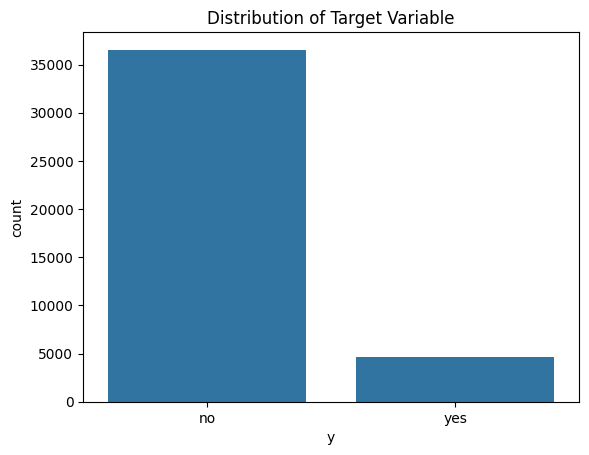

In [8]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='y', data=df)
plt.title("Distribution of Target Variable")
plt.show()

## Data Preparation

In [ ]:
# Remove Duplicates
# Justification: Duplicate records may bias model training and evaluation.

print("Duplicates:", df.duplicated().sum())

df = df.drop_duplicates()

Duplicates: 12


In [ ]:
# Identify variables containing unknown values
# Justification - "Unknown" represents missing information. Replacing with the mode preserves sample size and reduces information loss.
for col in df.columns:
    if df[col].dtype == 'object':
        if 'unknown' in df[col].unique():
            print(col)

In [ ]:
# Encode Target Variable
# Justification - Machine learning algorithms require numerical target labels
df['y'] = df['y'].map({
    'no':0,
    'yes':1
})


In [14]:
# Separate Features and Target
X = df.drop('y', axis=1)
y = df['y']

# One-Hot Encode Categorical Variables - Most algorithms cannot directly handle text categories
X = pd.get_dummies(X, drop_first=True)

In [15]:
# Train/Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,     #70% training data and 30% testing data
    random_state=42,
    stratify=y          #Stratification preserves class proportions
)

In [16]:
# Feature Scaling - Required for algorithms such as Logistic Regression, SVM, and Neural Networks
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Establish Majority-Class Baseline
#### Before building sophisticated models, a baseline must be established. A majority-class classifier predicts only the most common class for every observation

In [ ]:
y_train.value_counts()

y
0    25576
1     3247
Name: count, dtype: int64

In [ ]:
# Determine Majority Class
majority_class = y_train.mode()[0]
print("Majority Class:", majority_class)

Majority Class: 0


In [ ]:
# Create Baseline Predictions
import numpy as np

baseline_predictions = np.full(
    shape=len(y_test),
    fill_value=majority_class
)

In [24]:
# Evaluate Baseline
from sklearn.metrics import accuracy_score

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Accuracy:",
      round(baseline_accuracy,4))

Baseline Accuracy: 0.8873


In [25]:
# Classification Report
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    baseline_predictions
))

              precision    recall  f1-score   support

           0       0.89      1.00      0.94     10961
           1       0.00      0.00      0.00      1392

    accuracy                           0.89     12353
   macro avg       0.44      0.50      0.47     12353
weighted avg       0.79      0.89      0.83     12353



c:\Users\skamutungye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\skamutungye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\skamutungye\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

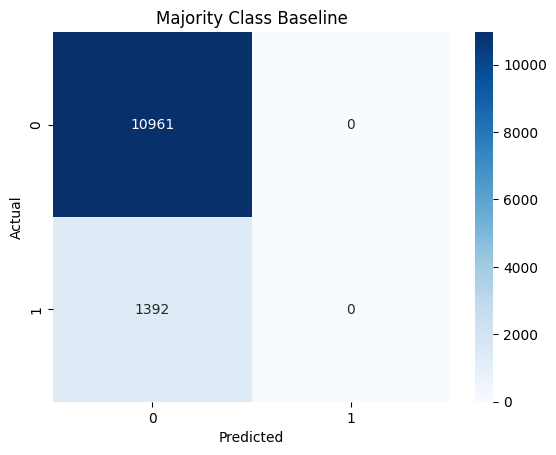

In [26]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    baseline_predictions
)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.title("Majority Class Baseline")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()